In [12]:
# Importar los paquetes y funciones necesarios
import numpy as np # para cálculos numéricos
import pandas as pd # para procesar datos y leer o escribir archivos
import matplotlib.pyplot as plt # para visualizar diferentes tipos de gráficas
%matplotlib inline
# para mostrar las gráficas de matplotlib junto al código en el cuaderno
import seaborn as sns # para visualización
import warnings # para ocultar advertencias
warnings.filterwarnings('ignore')

In [21]:
# Leer el conjunto de datos
sales = pd.read_csv('Advertising.csv')
sales

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,14.0
197,177.0,9.3,6.4,14.8
198,283.6,42.0,66.2,25.5


In [22]:
# Examinar la variable respuesta
sales['Sales'].describe()

count    200.000000
mean      15.130500
std        5.283892
min        1.600000
25%       11.000000
50%       16.000000
75%       19.050000
max       27.000000
Name: Sales, dtype: float64

<AxesSubplot:>

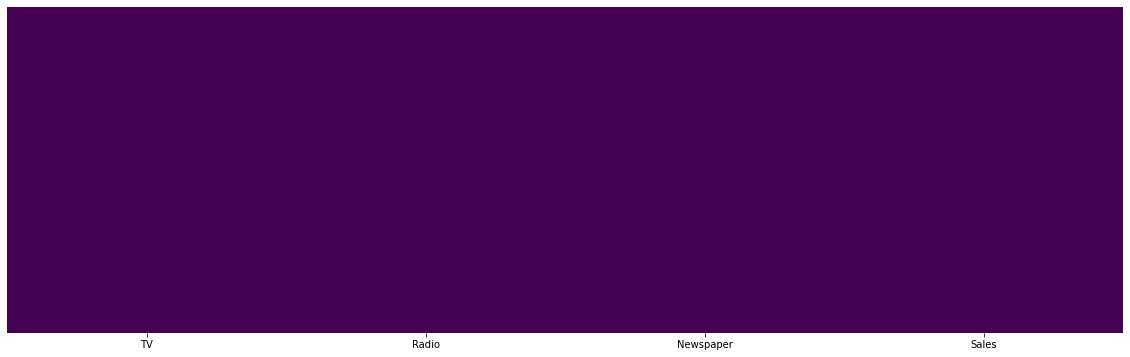

In [24]:
plt.figure(figsize=(20, 6))
sns.heatmap(sales.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [8]:
# Eliminar las filas con algún valor faltante
#sales.dropna(inplace=True)

<AxesSubplot:>

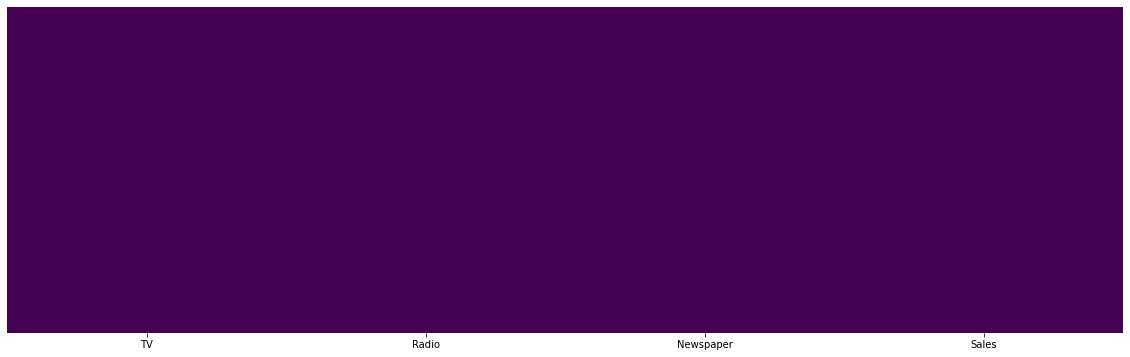

In [9]:
#plt.figure(figsize=(20, 6))
#sns.heatmap(sales.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [25]:
# Verificar las dimensiones de la base
sales.shape

(200, 4)

In [26]:
# Definir X e y
X = sales.drop('Sales', axis=1) #Excluimos la columna Sales (Axis=1 ->Eliminamos columna)
y = sales['Sales']
#Buscamos predecir las ventas a partir de la inversión publicitaria.

In [27]:
# Dividir los datos en entrenamiento y prueba
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size = 0.3,
                                                  random_state=1)

In [28]:
# Estandarizamos las variables explicativas para Ridge y Lasso
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#En este caso estandarizamos porque las variables tienen escalas diferentes,
#y queremos que Ridge y Lasso las penalice de manera comparable

### Regresión lineal. 

In [31]:
# Construir un modelo de regresión lineal
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
linreg.fit(X_train, y_train) #Estimamos los coeficientes utilizando datos del entrenamiento

LinearRegression()

In [32]:
print ("INTERCEPT : ",linreg.intercept_)
print ("CO-EFFICIENT : ",linreg.coef_)

INTERCEPT :  14.847857142857142
CO-EFFICIENT :  [ 4.76446306  1.55877627 -0.03241007]


In [34]:
# Realizar predicciones de las 60 observaciones de prueba
y_pred = linreg.predict(X_test)

# Ridge. 

In [37]:
# Alfa igual a cero equivale a regresión lineal
from sklearn.linear_model import Ridge
ridgereg = Ridge(alpha=0)
ridgereg.fit(X_train, y_train)
y_pred = ridgereg.predict(X_test)
# Calcular R², MAE, MSE y RMSE

from sklearn import metrics
from sklearn.metrics import r2_score
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

R-Square Value 0.9071151423684273
mean_absolute_error : 1.1947417134056741
mean_squared_error :  2.370659971225658
root_mean_squared_error :  1.5396947656031237


Alfa controla que tanto queremos reducir los coeficientes para evitar el sobreajuste.

Las variables independientes explican el 90.7% de la variabilidad de las ventas
Nuestras predicciones tienen un error de aprox. 1.19 unidades de ventas



In [39]:
# Probar alfa igual a 0.1
ridgereg = Ridge(alpha=0.1)
ridgereg.fit(X_train, y_train)
y_pred = ridgereg.predict(X_test)

# Calcular R², MAE, MSE y RMSE
from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

R-Square Value 0.9071379756426746
mean_absolute_error : 1.1951866992188351
mean_squared_error :  2.370077207461462
root_mean_squared_error :  1.53950550744759


En este caso aplicamos una pequeña penalización, el coeficiente de determinación aumentó ligeramente.
El error promedio empeoró un poco, ya que aumentó un poco

In [40]:
# Examinar los coeficientes
print(ridgereg.coef_)

#La penalizacón fue muy pequeña

[ 4.76105874  1.55747011 -0.03162932]


In [43]:
# Generamos 100 valores diferentes de alfa para que Ridge pruebe distintas 
#penalizaciones
alpha_range = np.logspace(-3, 3, 100)

array([1.00000000e-03, 1.14975700e-03, 1.32194115e-03, 1.51991108e-03,
       1.74752840e-03, 2.00923300e-03, 2.31012970e-03, 2.65608778e-03,
       3.05385551e-03, 3.51119173e-03, 4.03701726e-03, 4.64158883e-03,
       5.33669923e-03, 6.13590727e-03, 7.05480231e-03, 8.11130831e-03,
       9.32603347e-03, 1.07226722e-02, 1.23284674e-02, 1.41747416e-02,
       1.62975083e-02, 1.87381742e-02, 2.15443469e-02, 2.47707636e-02,
       2.84803587e-02, 3.27454916e-02, 3.76493581e-02, 4.32876128e-02,
       4.97702356e-02, 5.72236766e-02, 6.57933225e-02, 7.56463328e-02,
       8.69749003e-02, 1.00000000e-01, 1.14975700e-01, 1.32194115e-01,
       1.51991108e-01, 1.74752840e-01, 2.00923300e-01, 2.31012970e-01,
       2.65608778e-01, 3.05385551e-01, 3.51119173e-01, 4.03701726e-01,
       4.64158883e-01, 5.33669923e-01, 6.13590727e-01, 7.05480231e-01,
       8.11130831e-01, 9.32603347e-01, 1.07226722e+00, 1.23284674e+00,
       1.41747416e+00, 1.62975083e+00, 1.87381742e+00, 2.15443469e+00,
      

In [44]:
# Seleccionar el mejor alfa con RidgeCV
from sklearn.linear_model import RidgeCV
ridgeregcv = RidgeCV(alphas=alpha_range, scoring='neg_mean_squared_error')

ridgeregcv.fit(X_train, y_train)
ridgeregcv.alpha_

#En este caso el progrema seleccionó 0.2310 porque obtuvo el menor MSE durante la validación

0.23101297000831605

In [45]:
# El método predict utiliza el mejor valor de alfa
y_pred = ridgeregcv.predict(X_test)
# Calcular R², MAE, MSE y RMSE

from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

R-Square Value 0.907166283004601
mean_absolute_error : 1.1957688230549819
mean_squared_error :  2.3693547309295373
root_mean_squared_error :  1.5392708439158904


Al comparar la regresión lineal con Ridge, observamos que ambos modelos obtuvieron resultados muy
parecidos, con un R² de aproximadamente 90.7%. Sin embargo, Ridge logró reducir ligeramente el 
RMSE de 1.5397 a 1.5393, utilizando un alfa de 0.2310. Esto es bueno porque conseguimos disminuir
un poco el error de predicción al aplicar regularización, aunque la mejora fue mínima.

### Lasso.

In [47]:
# Probar alfa igual a 0.001 y examinar los coeficientes
from sklearn.linear_model import Lasso
lassoreg = Lasso(alpha=0.001)
lassoreg.fit(X_train, y_train)
print(lassoreg.coef_)
#Por ahora Lasso no elimina ninguna variable del modelo

[ 4.76341034  1.55707404 -0.0306455 ]


In [48]:
# Probar alfa igual a 0.01 y examinar los coeficientes
lassoreg = Lasso(alpha=0.01)
lassoreg.fit(X_train, y_train)
print(lassoreg.coef_)

[ 4.75392084  1.54203073 -0.01487642]


Al aumentar alfa, observamos que Lasso reduce más los coeficientes, especialmente el de Newspaper, que se acerca todavía más a cero. Sin embargo, ninguna variable ha sido eliminada del modelo, ya que los tres coeficientes siguen siendo diferentes de cero.

# Calcular RMSE (para alfa igual a 0.01)
y_pred = lassoreg.predict(X_test)
# Calcular MAE, MSE y RMSE
# Calcular R², MAE, MSE y RMSE

from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

Con alfa = 0.01, Lasso obtuvo un R² de 90.72% y un RMSE de 1.5393, mejorando ligeramente los resultados de la regresión lineal. Sin embargo, la mejora fue mínima, por lo que ambos modelos tienen una capacidad predictiva muy similar.

In [51]:
# Seleccionar el mejor alfa con LassoCV
from sklearn.linear_model import LassoCV
lassoregcv = LassoCV(n_alphas=100, random_state=1)
lassoregcv.fit(X_train, y_train)
print('alpha : ',lassoregcv.alpha_)

alpha :  0.09031063351611099


LassoCV seleccionó un alfa de 0.09031 mediante validación cruzada. Ahora utilizaremos este valor para evaluar las predicciones y comprobar si mejora los resultados de la regresión lineal y Ridge.

In [53]:
# Examinar los coeficientes
print(lassoregcv.coef_)

[4.67569737 1.4584943  0.        ]


Con el alfa seleccionado de 0.09031, Lasso redujo los coeficientes y eliminó Newspaper del modelo. Esto significa que Lasso considera que TV y Radio son suficientes para realizar las predicciones, sin necesidad de incluir Newspaper.

In [54]:
# El método predict utiliza el mejor valor de alfa
y_pred = lassoregcv.predict(X_test)
# Calcular R², MAE, MSE y RMSE

from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

R-Square Value 0.905943034847549
mean_absolute_error : 1.2257572094850058
mean_squared_error :  2.4005751635677735
root_mean_squared_error :  1.5493789606057562


Lasso obtuvo un R de 90.59% y un RMSE de 1.5494, resultados ligeramente peores que los de la regresión lineal y Ridge. Sin embargo, logró eliminar Newspaper del modelo, utilizando únicamente TV y Radio para predecir las ventas. Aunque no mejoró la precisión, consiguió un modelo más sencillo con un desempeño muy similar.

## Conclusión final.
Elegiría Lasso ya que es un modelo más sencillo por el número de variables independientes que utiliza. Tiene un error un poquito más grande que el de Ridge, pero es casi nada, por lo que yo me quedaría con Lasso.